In [18]:
import requests

def get_gene_position(gene):
    url = f"https://rest.ensembl.org/lookup/symbol/human/{gene}?content-type=application/json"
    response = requests.get(url)
    if response.ok:
        gene_info = response.json()
        return gene_info["seq_region_name"], gene_info["start"], gene_info["end"]
    else:
        return None

gen_list = 'TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B', 'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'

for gene in gen_list:
    chr_name, start, end = get_gene_position(gene)
    print(f"{gene}: Chromosome {chr_name}, Start {start}, End {end}")


TGFBR1: Chromosome 9, Start 99104038, End 99154192
ACVR1B: Chromosome 12, Start 51951699, End 51997078
ACVR1C: Chromosome 2, Start 157526767, End 157628864
ACVRL1: Chromosome 12, Start 51906908, End 51923361
TGFBR2: Chromosome 3, Start 30606478, End 30694249
ACVR2A: Chromosome 2, Start 147844517, End 147930826
BMPR1B: Chromosome 4, Start 94757955, End 95158448
BMPR2: Chromosome 2, Start 202376327, End 202567751
AMHR2: Chromosome 12, Start 53423855, End 53431672
ACVR1: Chromosome 2, Start 157736251, End 157876330
BMPR1A: Chromosome 10, Start 86755786, End 86932825
ACVR2B: Chromosome 3, Start 38453890, End 38493142


In [33]:
import requests

def get_gene_position(gene):
    url = f"https://rest.ensembl.org/lookup/symbol/human/{gene}?content-type=application/json"
    response = requests.get(url)
    if response.ok:
        gene_info = response.json()
        return gene_info["seq_region_name"], gene_info["start"], gene_info["end"]
    else:
        return None

gen_list = 'TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B', 'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'

for gene in gen_list:
    chr_name, start, end = get_gene_position(gene)
    print(f"{gene}: Chromosome {chr_name}, Start {start}, End {end}")


TGFBR1: Chromosome 9, Start 99104038, End 99154192
ACVR1B: Chromosome 12, Start 51951699, End 51997078
ACVR1C: Chromosome 2, Start 157526767, End 157628864
ACVRL1: Chromosome 12, Start 51906908, End 51923361
TGFBR2: Chromosome 3, Start 30606478, End 30694249
ACVR2A: Chromosome 2, Start 147844517, End 147930826
BMPR1B: Chromosome 4, Start 94757955, End 95158448
BMPR2: Chromosome 2, Start 202376327, End 202567751
AMHR2: Chromosome 12, Start 53423855, End 53431672
ACVR1: Chromosome 2, Start 157736251, End 157876330
BMPR1A: Chromosome 10, Start 86755786, End 86932825
ACVR2B: Chromosome 3, Start 38453890, End 38493142


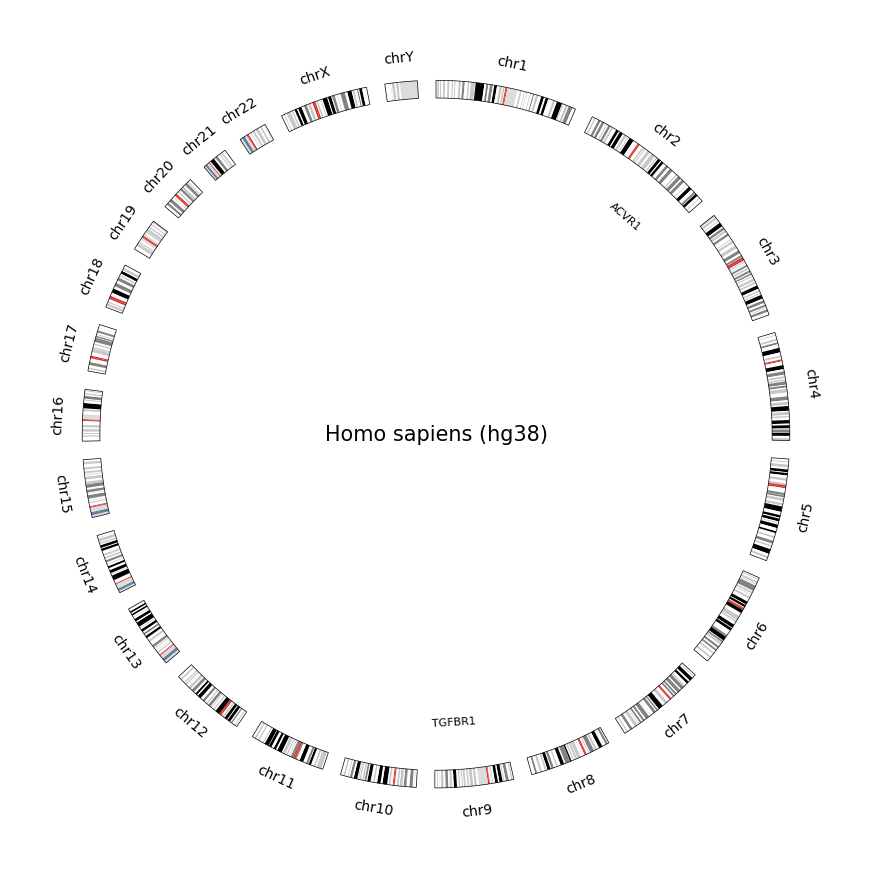

In [35]:
from pycirclize import Circos
from pycirclize.utils import load_eukaryote_example_dataset

# Load hg38 dataset
chr_bed_file, cytoband_file, _ = load_eukaryote_example_dataset("hg38")

# Initialize Circos from BED chromosomes
circos = Circos.initialize_from_bed(chr_bed_file, space=3)
circos.text("Homo sapiens (hg38)", size=15)

# Add cytoband tracks from cytoband file
circos.add_cytoband_tracks((95, 100), cytoband_file)

# Plot chromosome name
for sector in circos.sectors:
    sector.text(sector.name, size=10)

# Example of gene names by chromosome
gene_positions = {
    "chr9": [(99104038, "TGFBR1")],
    "chr2": [(157736251, "ACVR1")],
    # Add more genes as necessary
}

# Adding gene names inside the sectors
for sector in circos.sectors:
    if sector.name in gene_positions:
        for pos, gene_name in gene_positions[sector.name]:
            # Place gene name inside the circle
            sector.text(gene_name, r=80, x=pos, size=8, color='black')  # Adjust r to move inside

fig = circos.plotfig()



TypeError: Axes.text() got multiple values for argument 'y'

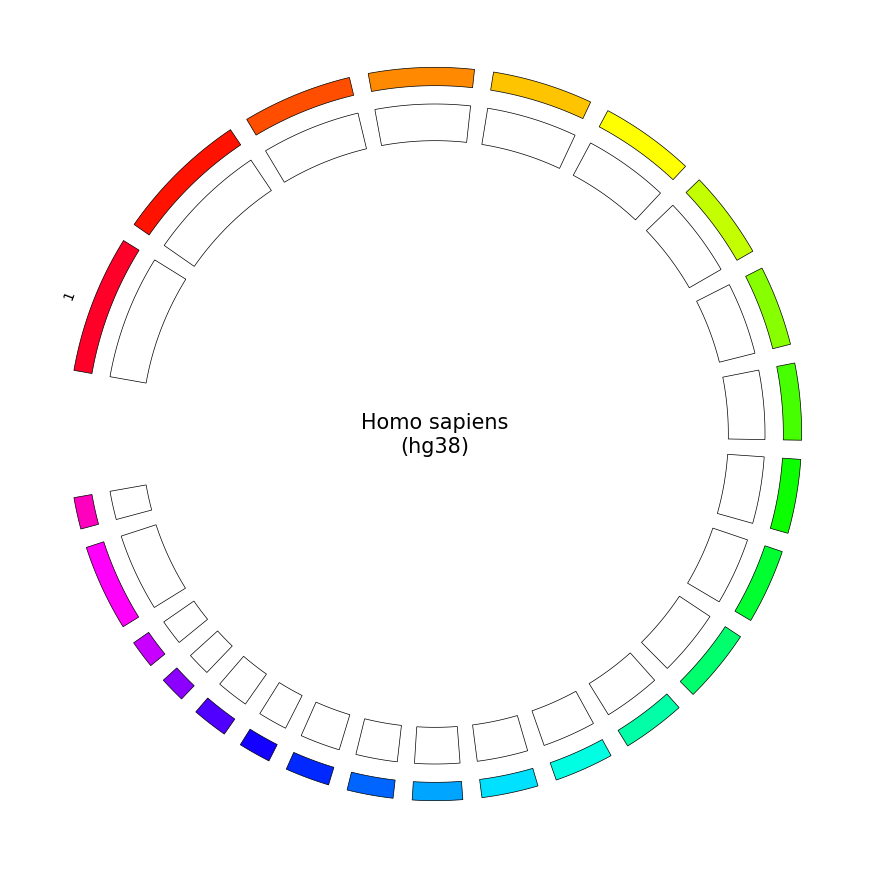

In [26]:
from pycirclize import Circos
from pycirclize.utils import ColorCycler, load_eukaryote_example_dataset
import numpy as np

# Cargar el dataset hg38
chr_bed_file = load_eukaryote_example_dataset("hg38")[0]

# Inicializar Circos desde los cromosomas del archivo BED
circos = Circos.initialize_from_bed(chr_bed_file, start=-80, end=260, space=3, endspace=False)
circos.text("Homo sapiens\n(hg38)", size=15)

# Crear un diccionario de colores para los cromosomas
ColorCycler.set_cmap("gist_rainbow")
chr_names = [s.name for s in circos.sectors]
colors = ColorCycler.get_color_list(len(chr_names))
chr_name2color = {name: color for name, color in zip(chr_names, colors)}

# Ejemplo de nombres de genes por cromosoma
gene_positions = {
    "chr1": [(100000, "GENE1"), (200000, "GENE2")],
    "chr2": [(150000, "GENE3")],
    # Agrega más genes según sea necesario
}

for sector in circos.sectors:
    # Graficar la pista externa del cromosoma
    sector.text(sector.name.replace("chr", ""))
    color = chr_name2color[sector.name]
    outer_track = sector.add_track((95, 100))
    outer_track.axis(fc=color)

    # Agregar nombres de genes
    if sector.name in gene_positions:
        for pos, gene_name in gene_positions[sector.name]:
            sector.text(gene_name, x=pos, y=97, size=8, color='black')  # Ajusta las coordenadas según sea necesario

    # Código para agregar otras pistas como se muestra en tu ejemplo original
    step = 10000000
    x = np.arange(sector.start + (step / 2), sector.end - (step / 2), step)
    y = np.random.randint(0, 100, size=len(x))
    
    # Scatter track
    track1 = sector.add_track((80, 90), r_pad_ratio=0.1)
    track1.axis()
    track1.scatter(x, y, s=6, color="red")
    # Línea, barras, etc. (como en tu código original) se agregan aquí...

fig = circos.plotfig()


In [53]:
# Define the gene positions
gene_positions = [
    ("chr9", 99104038, 99154192),  # TGFBR1
    ("chr12", 51951699, 51997078),  # ACVR1B
    ("chr2", 157526767, 157628864),  # ACVR1C
    ("chr12", 51906908, 51923361),  # ACVRL1
    ("chr3", 30606478, 30694249),  # TGFBR2
    ("chr2", 147844517, 147930826),  # ACVR2A
    ("chr4", 94757955, 95158448),  # BMPR1B
    ("chr2", 202376327, 202567751),  # BMPR2
    ("chr12", 53423855, 53431672),  # AMHR2
    ("chr2", 157736251, 157876330),  # ACVR1
    ("chr10", 86755786, 86932825),  # BMPR1A
    ("chr3", 38453890, 38493142),  # ACVR2B
]

# Create a BED file
with open("regions22.bed", "w") as f:
    for chromosome, start, end in gene_positions:
        f.write(f"{chromosome}\t{start}\t{end}\n")


ValueError: Length mismatch: Expected axis has 1 elements, new values have 3 elements

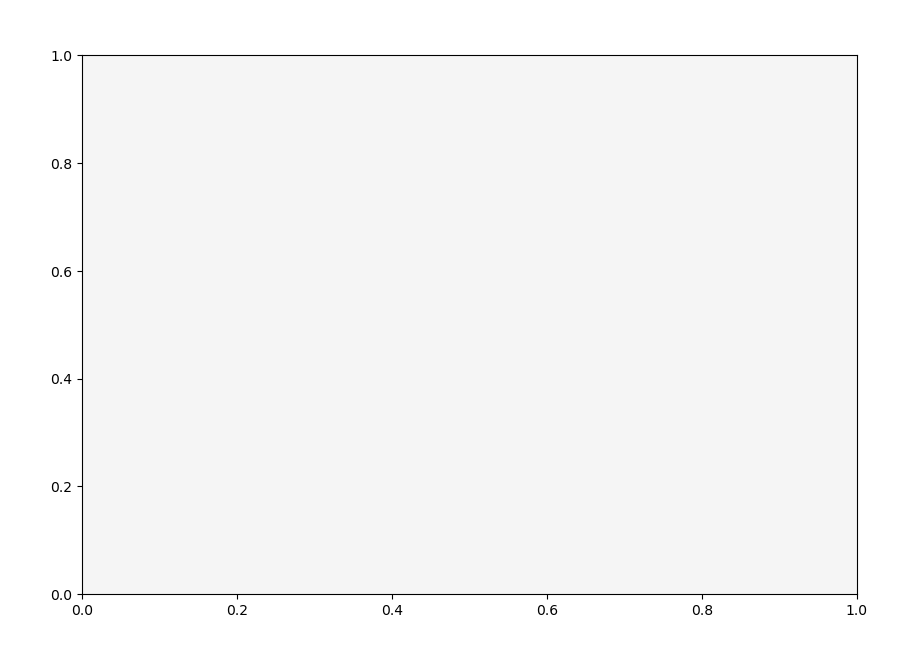

In [54]:

import karyopype.karyopype as kp

# plot two sets of regions
kp.plot_karyopype("hg38", ["regions22.bed"])

In [58]:

import karyopype as kp
kp.plot_karyopyp("hg38", "/path/to/regions.bed", savefig=True)

AttributeError: module 'karyopype' has no attribute 'plot_karyopyp'